In [ ]:
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
students = pd.read_csv("students_100.csv")
print(students.shape)

x = torch.tensor(
    students[["study_hours", "phone_hours"]].values,
    dtype=torch.float32
)
y = torch.tensor(students["maths"].values, dtype=torch.float32)
print(x.shape)
print(y.shape)

(100, 8)
torch.Size([100, 2])
torch.Size([100])


In [3]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 1),
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

In [4]:
losses = []
for epoch in range(300):
    guess = model(x)
    loss = loss_fn(guess, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 50 == 0:
        print(f"epoch {epoch:3}: loss = {loss.item():.1f}")

c:\Users\rohaa\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([100])) that is different to the input size (torch.Size([100, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


epoch   0: loss = 3023.5
epoch  50: loss = 283.6
epoch 100: loss = 245.2
epoch 150: loss = 217.8
epoch 200: loss = 190.2
epoch 250: loss = 170.6


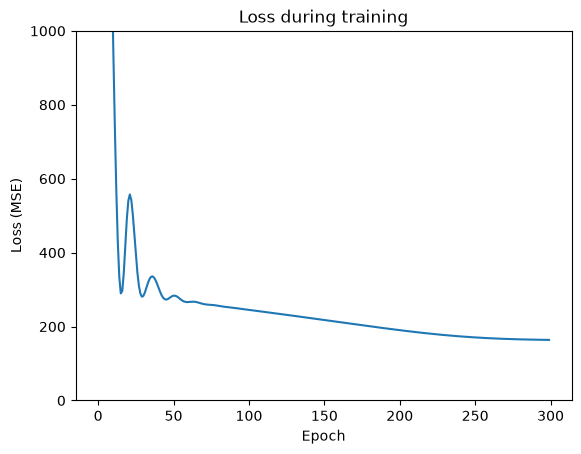

In [5]:
plt.plot(losses)
plt.ylim(0, 1000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

In [6]:
with torch.no_grad():
    new_student = torch.tensor([[3, 2]], dtype=torch.float32)
    print("3 study hours, 2 phone hours ->", round(model(new_student).item(), 1), "marks")

3 study hours, 2 phone hours -> 52.7 marks
